# Offline SS reconfiguration counts

Check every model in `github/test/reconfiguration/models` against **SS (SRAM)** and **SS_T (TCAM)**, then compare every ordered pair of distinct model files within each system. Different files of the same model type are included. SVM, LR, NB, SLP, and KM models are evaluated only for SS; they are excluded from SS_T conversion and model pairs.

Label encoders are loaded beside the models; selectors are loaded from `github/test/reconfiguration/selectors`. IsolationForest models do not require a label encoder.

Run the shared setup/functions cell first, then the SS and SS_T result cells independently. Conversion builds entry objects in memory only. No BFRT scripts, JSON artifacts, PCAPs, installed snapshots, SDE, or network connections are used.

**Differential:** ADD = new keys, MOD = shared keys with changed action or parameters, DEL = removed keys. Unchanged entries require no operation.
**Delete-then-add:** ADD = all destination entries, MOD = 0, DEL = all source entries.
Pairs involving a failed model remain visible with unavailable counts and a reason. Run the cells in order.

In [30]:
import sys
from itertools import permutations
from pathlib import Path

import joblib
import pandas as pd
from IPython.display import display

# Locate the standalone github directory from the notebook or project working directory.
candidates = [
    candidate
    for parent in (Path.cwd(), *Path.cwd().parents)
    for candidate in (parent, parent / "artifact_evaluation" / "github")
]
GITHUB_ROOT = next(
    (path.resolve() for path in candidates
     if (path / "utils" / "model_conversion.py").is_file()),
    None,
)
if GITHUB_ROOT is None:
    raise FileNotFoundError("Run from the github directory, its test directory, or the project root.")
sys.path.insert(0, str(GITHUB_ROOT))
from utils import model_conversion as conversion

if Path(conversion.__file__).resolve().parent != GITHUB_ROOT / "utils":
    raise ImportError("Another utils package is cached; restart the kernel and run this notebook first.")

SYSTEMS = {"SS": False, "SS_T": True}
MODELS_DIR = GITHUB_ROOT / "test" / "reconfiguration" / "models"
SELECTORS_DIR = MODELS_DIR.parent / "selectors"
if not MODELS_DIR.is_dir():
    raise FileNotFoundError(f"Model directory does not exist: {MODELS_DIR}")
model_paths = sorted(
    path for path in MODELS_DIR.glob("*.joblib")
    if not path.stem.endswith(("_selector", "_label_encoder"))
)
print(f"Found {len(model_paths)} model files in {MODELS_DIR}")
if not model_paths:
    print("No model files found; add models and label encoders here, and selectors to the sibling selectors directory.")


def check_models(paths, system):
    tcam = SYSTEMS[system]
    entry_cache, failures = {}, {}
    for path in paths:
        key = (system, path.stem)
        try:
            model = joblib.load(path)
            if tcam and isinstance(model, (
                conversion.SVC, conversion.LogisticRegression, conversion.GaussianNB,
                conversion.CategoricalNB, conversion.Perceptron, conversion.KMeans,
            )):
                continue
            selector = joblib.load(SELECTORS_DIR / f"{path.stem}_selector.joblib")
            label_encoder = (
                None if isinstance(model, conversion.IsolationForest)
                else joblib.load(path.with_name(f"{path.stem}_label_encoder.joblib"))
            )
        except Exception as error:
            failures[key] = f"Load failed: {type(error).__name__}: {error}"
            continue
        try:
            entries, _ = conversion.convert_model_entries(
                model, {}, tcam, selector=selector, label_encoder=label_encoder,
            )
            entry_cache[key] = entries
        except Exception as error:
            failures[key] = f"Conversion failed: {type(error).__name__}: {error}"
    return entry_cache, failures


def compare_models(paths, entry_cache, failures, system):
    rows = []
    eligible_models = [
        path.stem for path in paths
        if (system, path.stem) in entry_cache or (system, path.stem) in failures
    ]
    for source, destination in permutations(eligible_models, 2):
        keys = [(system, source), (system, destination)]
        reason = "; ".join(f"{key[1]}: {failures[key]}" for key in keys if key in failures)
        if not reason:
            old_entries, new_entries = (entry_cache[key] for key in keys)
            add, mod, delete, _ = conversion.classify_operations(old_entries, new_entries)
            counts = {
                "differential": (len(add), len(mod), len(delete)),
                "delete_then_add": (len(new_entries), 0, len(old_entries)),
            }
        for mode in ("differential", "delete_then_add"):
            add, mod, delete = (pd.NA, pd.NA, pd.NA) if reason else counts[mode]
            rows.append({
                "system": system, "source": source, "destination": destination,
                "mode": mode, "status": "skipped" if reason else "ok",
                "ADD": add, "MOD": mod, "DEL": delete, "reason": reason,
            })
    results = pd.DataFrame(rows, columns=[
        "system", "source", "destination", "mode", "status", "ADD", "MOD", "DEL", "reason",
    ])
    results[["ADD", "MOD", "DEL"]] = results[["ADD", "MOD", "DEL"]].astype("Int64")
    return results


def run_reconfiguration(system):
    entry_cache, failures = check_models(model_paths, system)
    return compare_models(model_paths, entry_cache, failures, system)

Found 18 model files in C:\Users\zhudi.DESKTOP-AL823SE\OneDrive - University of Virginia\Projects\Shapeshifter\artifact_evaluation\github\test\reconfiguration\models


In [28]:
ss_results = run_reconfiguration("SS")
print(f"SS: {len(ss_results)} comparisons")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ss_results)

C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.5.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RFE from version 1.5.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: Inconsist

SS: 612 comparisons


,system,source,destination,mode,status,ADD,MOD,DEL,reason
0,SS,dt1,dt2,differential,ok,3420,1237,142,
1,SS,dt1,dt2,delete_then_add,ok,7468,0,4190,
2,SS,dt1,if1,differential,ok,17485,933,3111,
3,SS,dt1,if1,delete_then_add,ok,18564,0,4190,
4,SS,dt1,if2,differential,ok,34809,901,3183,
5,SS,dt1,if2,delete_then_add,ok,35816,0,4190,
6,SS,dt1,km1,differential,ok,215,500,3683,
7,SS,dt1,km1,delete_then_add,ok,722,0,4190,
8,SS,dt1,km2,differential,ok,623,900,3283,
9,SS,dt1,km2,delete_then_add,ok,1530,0,4190,


In [29]:
ss_t_results = run_reconfiguration("SS_T")
print(f"SS_T: {len(ss_t_results)} comparisons")
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(ss_t_results)

C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.5.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator RFE from version 1.5.2 when using version 1.7.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
C:\Users\zhudi.DESKTOP-AL823SE\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:442: Inconsist

SS_T: 112 comparisons


,system,source,destination,mode,status,ADD,MOD,DEL,reason
0,SS_T,dt1,dt2,differential,ok,287,366,130,
1,SS_T,dt1,dt2,delete_then_add,ok,796,0,639,
2,SS_T,dt1,if1,differential,ok,703,489,132,
3,SS_T,dt1,if1,delete_then_add,ok,1210,0,639,
4,SS_T,dt1,if2,differential,ok,892,493,132,
5,SS_T,dt1,if2,delete_then_add,ok,1399,0,639,
6,SS_T,dt1,rf1,differential,ok,562,412,132,
7,SS_T,dt1,rf1,delete_then_add,ok,1069,0,639,
8,SS_T,dt1,rf2,differential,ok,1100,491,132,
9,SS_T,dt1,rf2,delete_then_add,ok,1607,0,639,


## Baseline reconfiguration counts

ST and IIsy include their supported model families; LEO supports DT only. Baseline ADD/DEL counts use a shared target layout and delete-then-add (MOD = 0). Unsupported transitions and conversion/capacity failures retain missing counts and reasons in `baseline_sram_results` and `baseline_tcam_results`; their bars are omitted. Run this section before plotting. Counting uses only the standalone artifact and writes no generated files.

In [36]:
from utils import baseline_converters as baselines

# Counts use the same quantized feature domain as the SS converter.
# Baselines use delete-then-add; only SS-D uses differential updates.
BASELINE_SYSTEMS = {
    "SRAM": [("ST", "st"), ("IIsy", "iisy"), ("LEO", "leo_sram")],
    "TCAM": [("ST", "st_tcam"), ("IIsy", "iisy_range"), ("LEO", "leo_tcam")],
}
baseline_models, baseline_load_errors = {}, {}
for path in model_paths:
    try:
        baseline_models[path.stem] = joblib.load(path)
    except Exception as error:
        baseline_load_errors[path.stem] = f"Load failed: {type(error).__name__}: {error}"


def run_baseline_reconfiguration(memory):
    rows = []
    for label, target in BASELINE_SYSTEMS[memory]:
        for source, destination in permutations([path.stem for path in model_paths], 2):
            row = dict(system=label, source=source, destination=destination,
                       mode="delete_then_add", status="ok", reason="")
            try:
                errors = [baseline_load_errors[name] for name in (source, destination)
                          if name in baseline_load_errors]
                if errors:
                    raise ValueError("; ".join(errors))
                row.update(baselines.count_reconfiguration_operations(
                    baseline_models[source], baseline_models[destination], target,
                ))
            except baselines.UnsupportedTransitionError as error:
                row.update(status="unsupported", reason=str(error))
            except Exception as error:
                row.update(status="failed", reason=f"{type(error).__name__}: {error}")
            rows.append(row)
    frame = pd.DataFrame(rows, columns=ss_results.columns)
    frame[["ADD", "MOD", "DEL"]] = frame[["ADD", "MOD", "DEL"]].astype("Int64")
    print(f"{memory}: baseline transition coverage")
    display(frame.groupby(["system", "status"]).size().unstack(fill_value=0))
    failed = frame.loc[frame["status"].eq("failed")]
    if not failed.empty:
        display(failed.groupby(["system", "reason"]).size().rename("comparisons").reset_index())
    return frame


baseline_sram_results = run_baseline_reconfiguration("SRAM")
baseline_tcam_results = run_baseline_reconfiguration("TCAM")

SRAM: baseline transition coverage


status,failed,ok,unsupported
system,,,
IIsy,14,56,236
LEO,0,2,304
ST,4,8,294


,system,reason,comparisons
0,IIsy,ValueError: DT conversion failed: IIsy tree fe...,12
1,IIsy,ValueError: SVM conversion failed: 'SVC' objec...,2
2,ST,ValueError: DT conversion failed: SwitchTree R...,4


TCAM: baseline transition coverage


status,failed,ok,unsupported
system,,,
IIsy,0,56,250
LEO,0,2,304
ST,4,8,294


,system,reason,comparisons
0,ST,ValueError: DT conversion failed: SwitchTree R...,4


# Plotting

In [31]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import ScalarFormatter
import numpy as np

COMPARE_TRANSITIONS = [
    ("DT1", "RF1"), ("DT1", "RF2"), ("DT1", "IF1"), ("DT1", "XGB2"),
    ("DT2", "RF1"), ("DT2", "XGB1"), ("RF1", "IF2"), ("RF2", "XGB2"),
    ("IF1", "XGB1"), ("KM1", "NB1"),
]
EXCLUSIVE_TRANSITIONS = [
    ("DT1", "SVM1"), ("DT2", "SVM2"), ("RF1", "LR1"), ("XGB1", "KM1"),
    ("IF1", "NB1"), ("SVM1", "DT1"), ("SLP2", "RF2"), ("LR1", "SVM1"),
    ("NB2", "SLP1"),
]


def plot_operation_counts(results, transitions, system, title, baseline_results=None):
    if set(results["system"]) != {system}:
        raise ValueError(f"Expected results for {system} only")
    indexed = results.set_index(["source", "destination", "mode"])
    if not indexed.index.is_unique:
        raise ValueError("Duplicate comparison rows")
    modes = [("delete_then_add", "SS", ".."), ("differential", "SS-D", "//")]
    operations = ["ADD", "MOD", "DEL"]
    colors = ["#F7F7F7", "#4C78A8", "#D9D9D9"]
    counts = []
    for mode, _, _ in modes:
        values = []
        for source, destination in transitions:
            key = (source.lower(), destination.lower(), mode)
            if key not in indexed.index:
                raise ValueError(f"Missing {system} comparison: {source} -> {destination} ({mode})")
            row = indexed.loc[key]
            if row["status"] != "ok" or row[operations].isna().any():
                raise ValueError(f"Unavailable {system} comparison: {source} -> {destination}: {row['reason']}")
            values.append([int(row[operation]) for operation in operations])
        counts.append(values)
    if baseline_results is not None:
        baseline_indexed = baseline_results.set_index(["system", "source", "destination"])
        if not baseline_indexed.index.is_unique:
            raise ValueError("Duplicate baseline comparison rows")
        baseline_counts = []
        baseline_modes = [("delete_then_add", "ST", ""), ("delete_then_add", "IIsy", "\\\\"),
                          ("delete_then_add", "LEO", "xx")]
        for _, label, _ in baseline_modes:
            values = []
            for source, destination in transitions:
                key = (label, source.lower(), destination.lower())
                row = baseline_indexed.loc[key] if key in baseline_indexed.index else None
                values.append([int(row[operation]) for operation in operations]
                              if row is not None and row["status"] == "ok"
                              and not row[operations].isna().any() else [np.nan] * 3)
            baseline_counts.append(values)
        counts = baseline_counts + counts
        modes = baseline_modes + modes
    counts = np.asarray(counts)
    if not transitions or np.any(counts < 0):
        raise ValueError("Plotting requires transitions with nonnegative operation counts")

    with plt.rc_context({"font.family": "Times New Roman", "font.size": 20}):
        fig, ax = plt.subplots(figsize=(16, 8))
        x = np.arange(len(transitions))
        visible = np.isfinite(counts).all(axis=2)
        bar_width = 0.8 / visible.sum(axis=0).max()
        offsets = (visible.cumsum(axis=0) - (visible.sum(axis=0) + 1) / 2) * bar_width
        for mode_index, (_, _, hatch) in enumerate(modes):
            mask = visible[mode_index]
            positions = x[mask] + offsets[mode_index, mask]
            bottom = np.zeros(mask.sum())
            for operation_index, color in enumerate(colors):
                heights = counts[mode_index, mask, operation_index]
                ax.bar(positions, heights, width=bar_width * 0.9, bottom=bottom,
                       color=color, edgecolor="black", linewidth=0.8, hatch=hatch)
                bottom += heights
        ax.set_xticks(x)
        ax.set_xticklabels([f"{source}->{destination}" for source, destination in transitions],
                           rotation=25, ha="right")
        ax.set_ylabel("# Ops")
        ax.set_title(title)
        ax.set_ylim(0, max(1, np.nansum(counts, axis=2).max() * 1.15))
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_axisbelow(True)
        ax.grid(axis="y", alpha=0.25)
        formatter = ScalarFormatter(useMathText=False)
        formatter.set_scientific(True)
        formatter.set_powerlimits((3, 3))
        ax.yaxis.set_major_formatter(formatter)
        handles = [Patch(facecolor=color, edgecolor="black", label=operation)
                   for operation, color in zip(operations, colors)]
        handles += [Patch(facecolor="white", edgecolor="black", hatch=hatch, label=label)
                    for index, (_, label, hatch) in enumerate(modes) if visible[index].any()]
        fig.legend(handles=handles, loc="upper center", ncol=len(handles), fontsize=16)
        fig.tight_layout(rect=(0, 0, 1, 0.91))
    return fig

# Figure 10(a) and Figure 10(b)

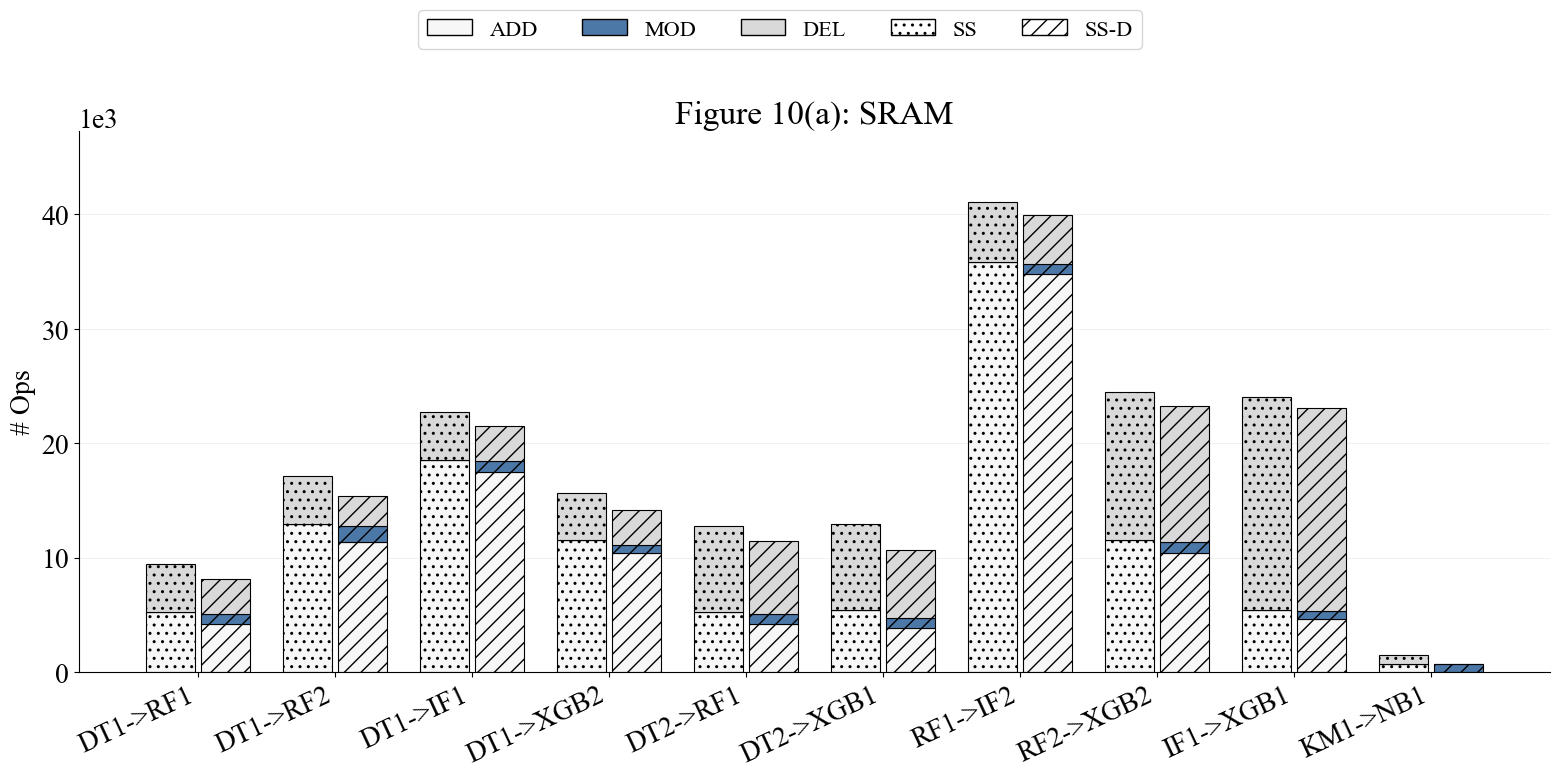

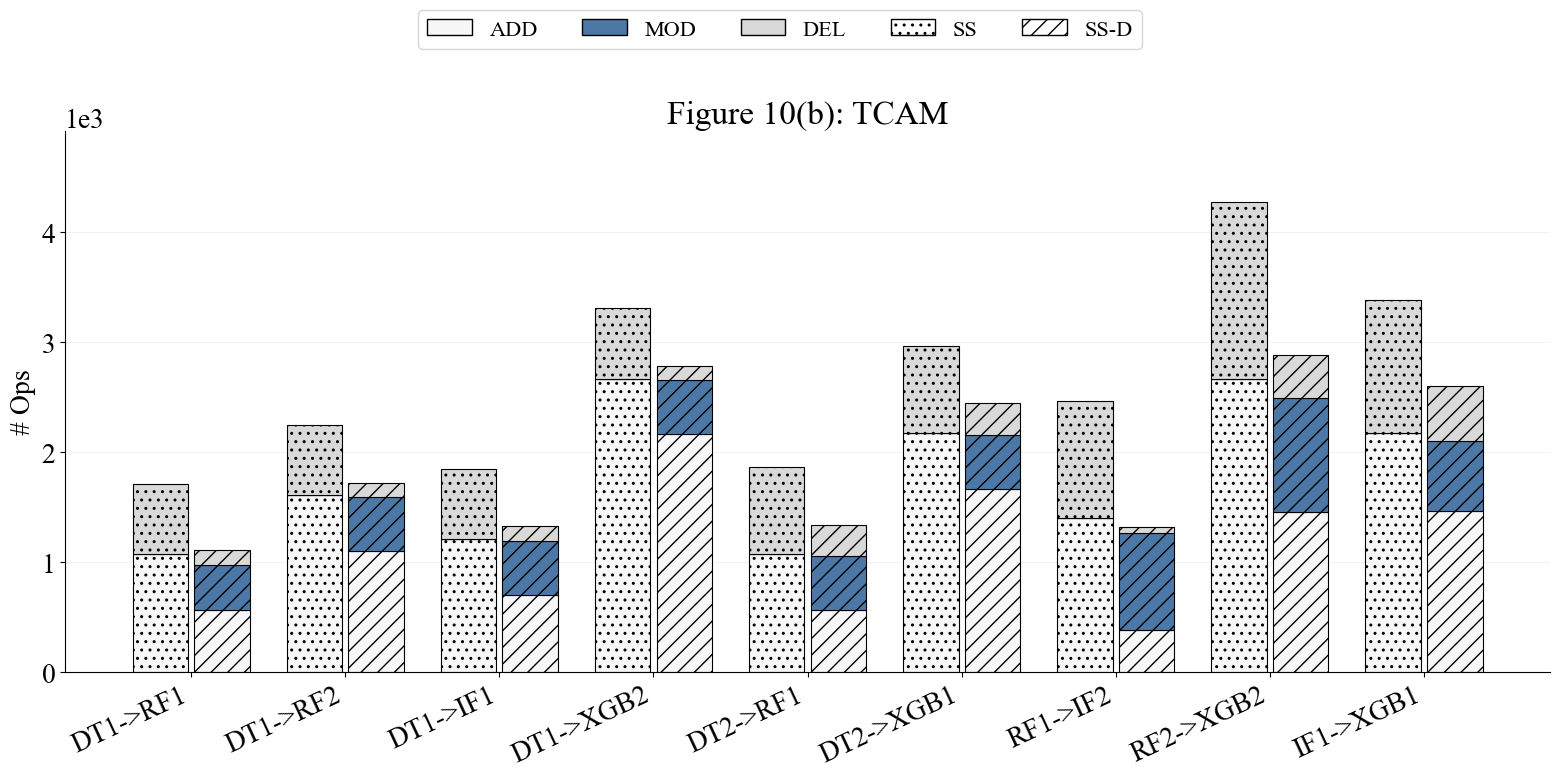

In [32]:
fig_10a = plot_operation_counts(
    ss_results, COMPARE_TRANSITIONS, "SS", "Figure 10(a): SRAM",
    baseline_results=baseline_sram_results,
)
plt.show()

# KM1 -> NB1 is excluded because SS_T does not support linear models.
tcam_transitions = [pair for pair in COMPARE_TRANSITIONS if pair != ("KM1", "NB1")]
fig_10b = plot_operation_counts(
    ss_t_results, tcam_transitions, "SS_T", "Figure 10(b): TCAM",
    baseline_results=baseline_tcam_results,
)
plt.show()

# Figure 11

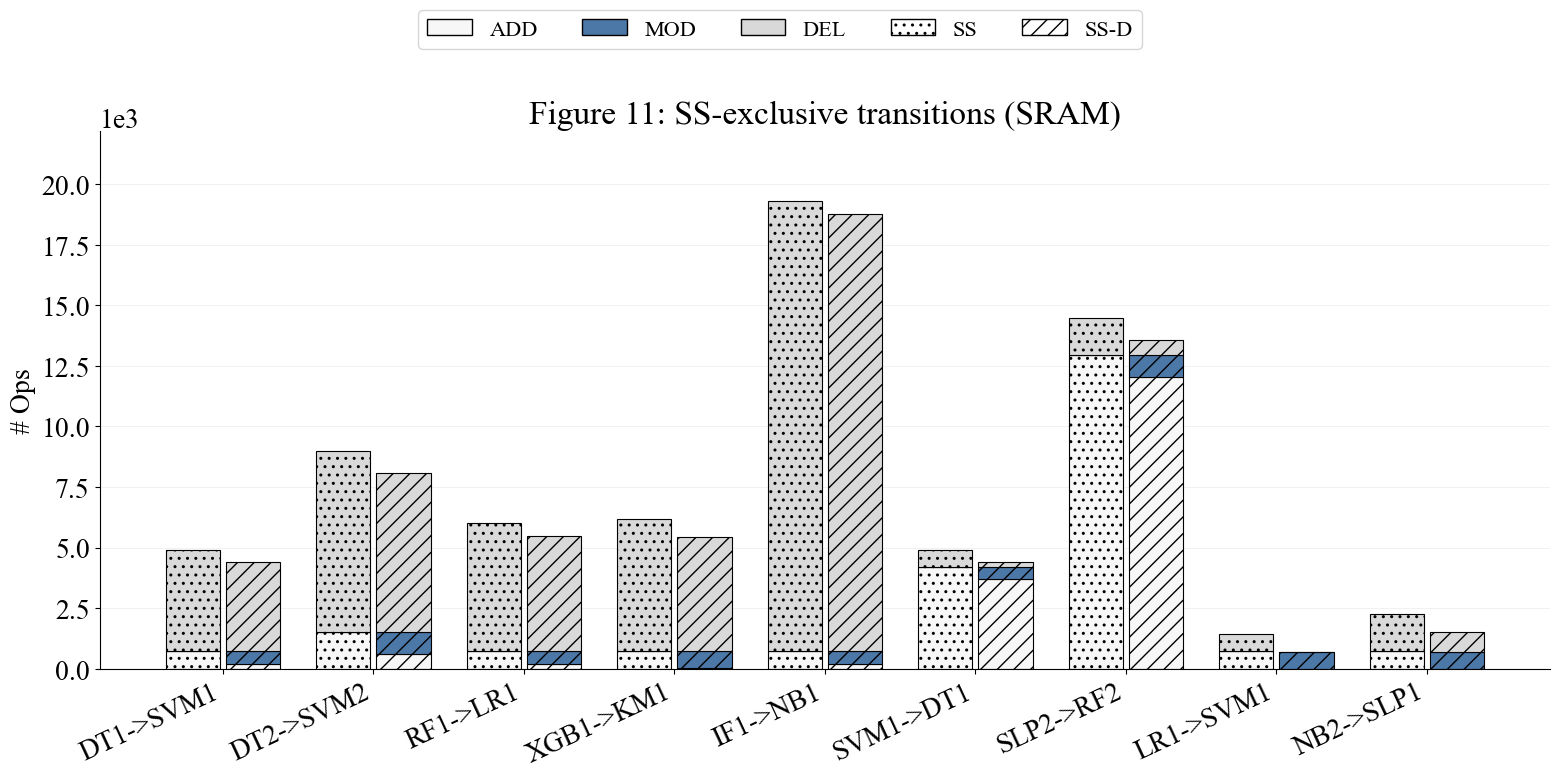

In [33]:
fig_11 = plot_operation_counts(
    ss_results, EXCLUSIVE_TRANSITIONS, "SS", "Figure 11: SS-exclusive transitions (SRAM)",
    baseline_results=baseline_sram_results,
)
plt.show()

# Figure 18(a) and Figure 18(b)

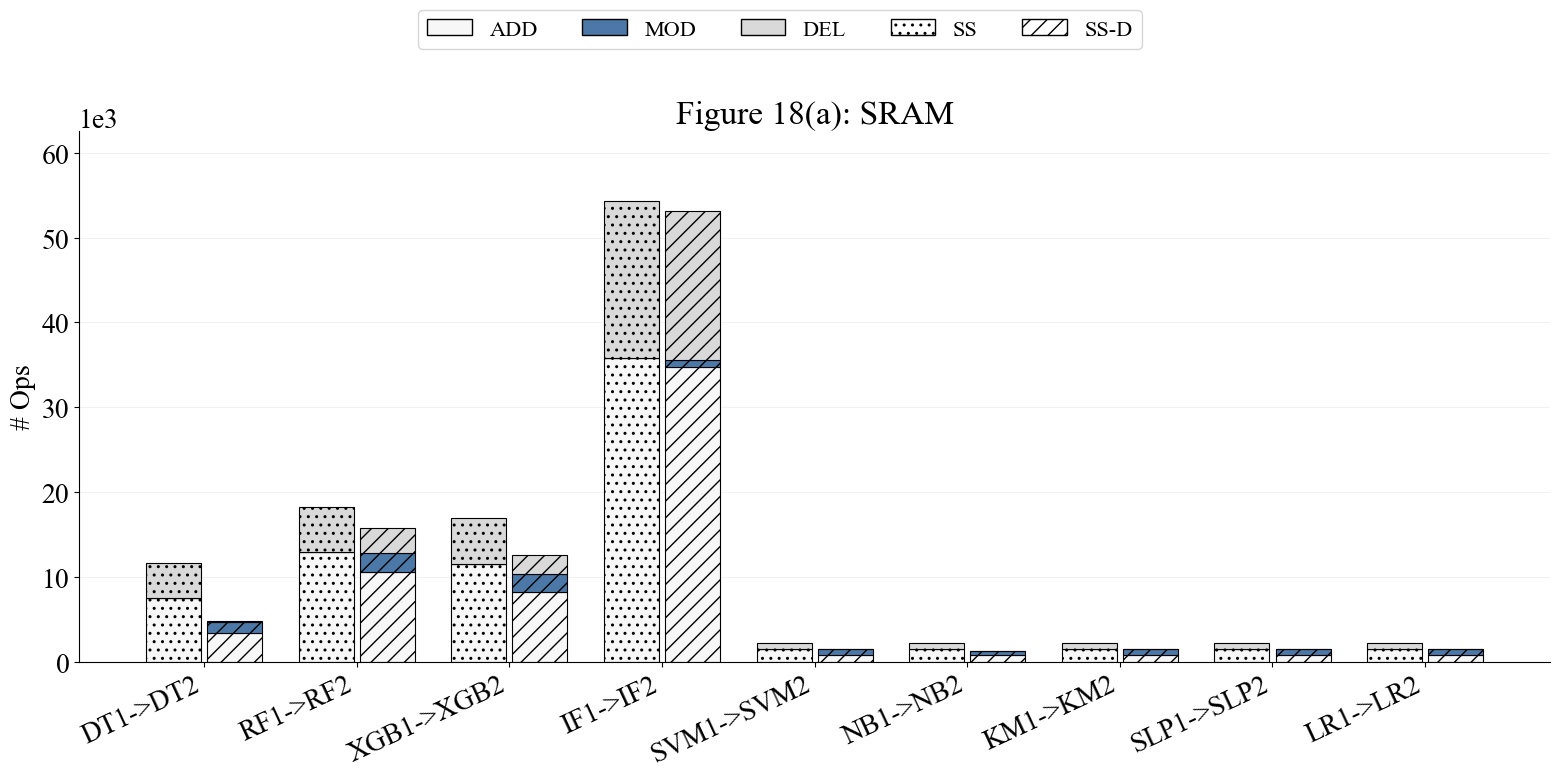

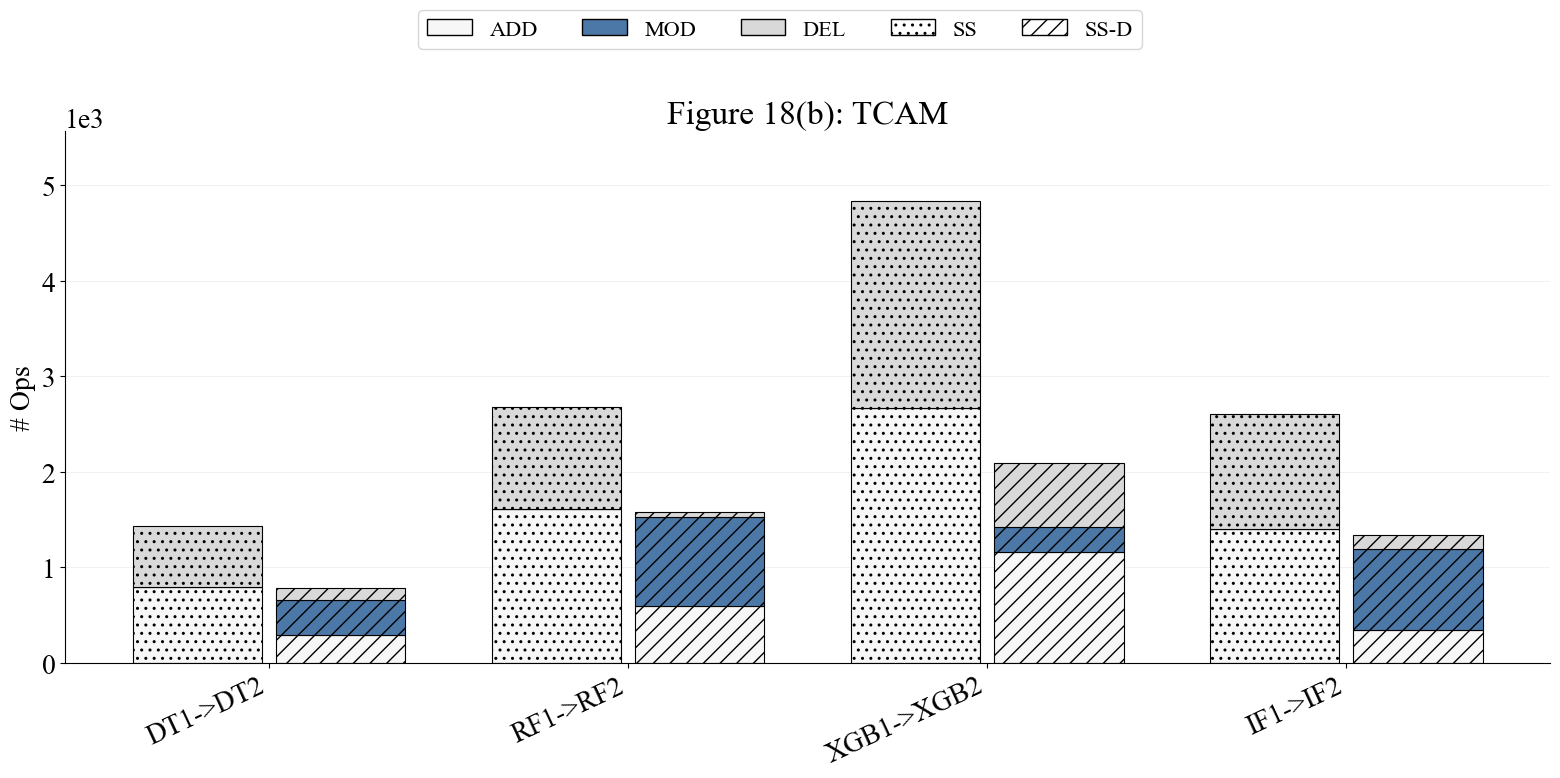

In [35]:
INTRA_TRANSITIONS = [
    ("DT1", "DT2"), ("RF1", "RF2"), ("XGB1", "XGB2"), ("IF1", "IF2"),
    ("SVM1", "SVM2"), ("NB1", "NB2"), ("KM1", "KM2"), ("SLP1", "SLP2"),
    ("LR1", "LR2"),
]

fig_18a = plot_operation_counts(
    ss_results, INTRA_TRANSITIONS, "SS", "Figure 18(a): SRAM",
    baseline_results=baseline_sram_results,
)
plt.show()

# SS_T supports only the DT, RF, XGB, and IF models in these transitions.
intra_tcam_transitions = [
    pair for pair in INTRA_TRANSITIONS
    if all(model.startswith(("DT", "RF", "XGB", "IF")) for model in pair)
]
fig_18b = plot_operation_counts(
    ss_t_results, intra_tcam_transitions, "SS_T", "Figure 18(b): TCAM",
    baseline_results=baseline_tcam_results,
)
plt.show()

# Figure 19(a) and Figure 19(b)

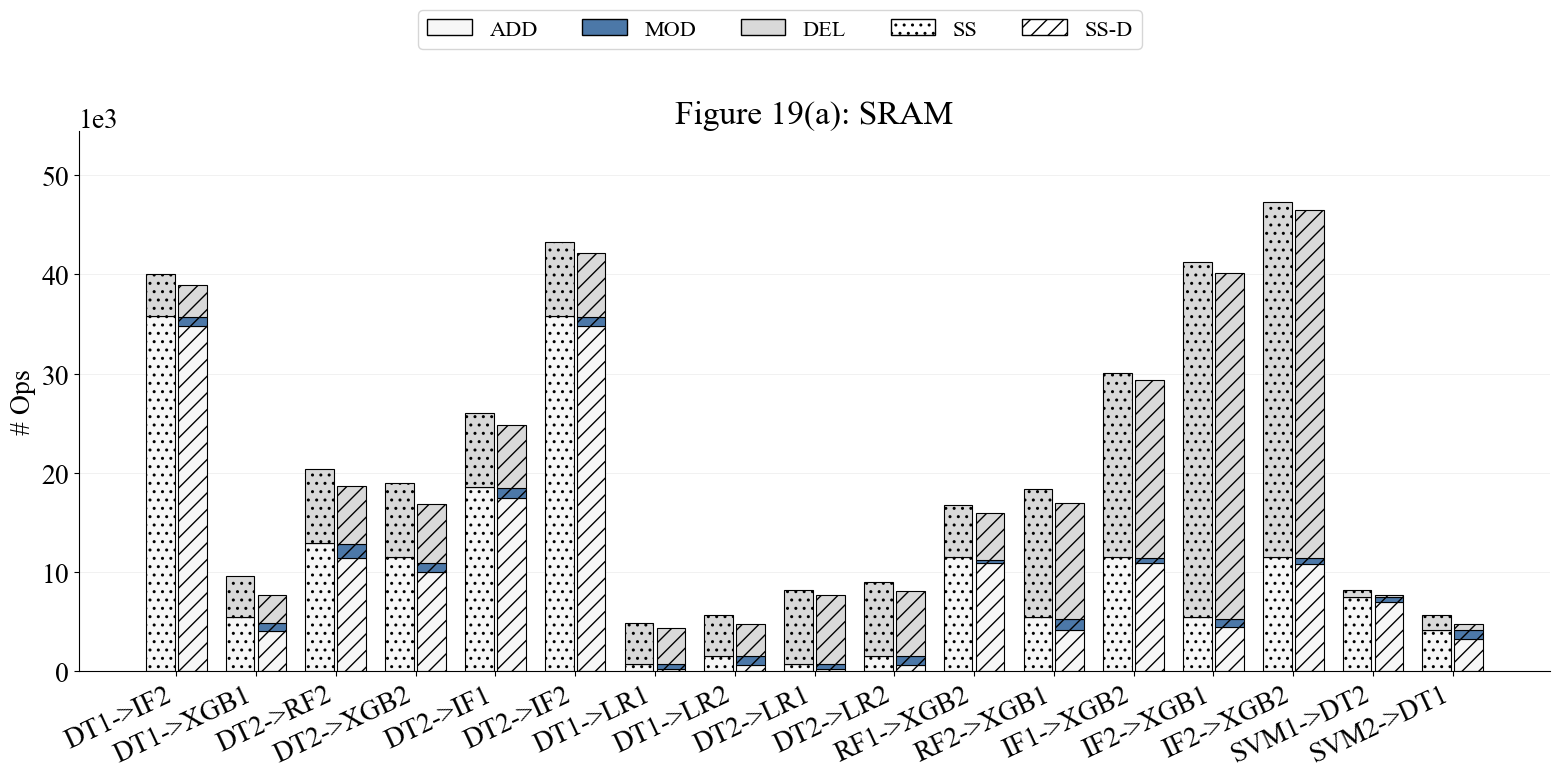

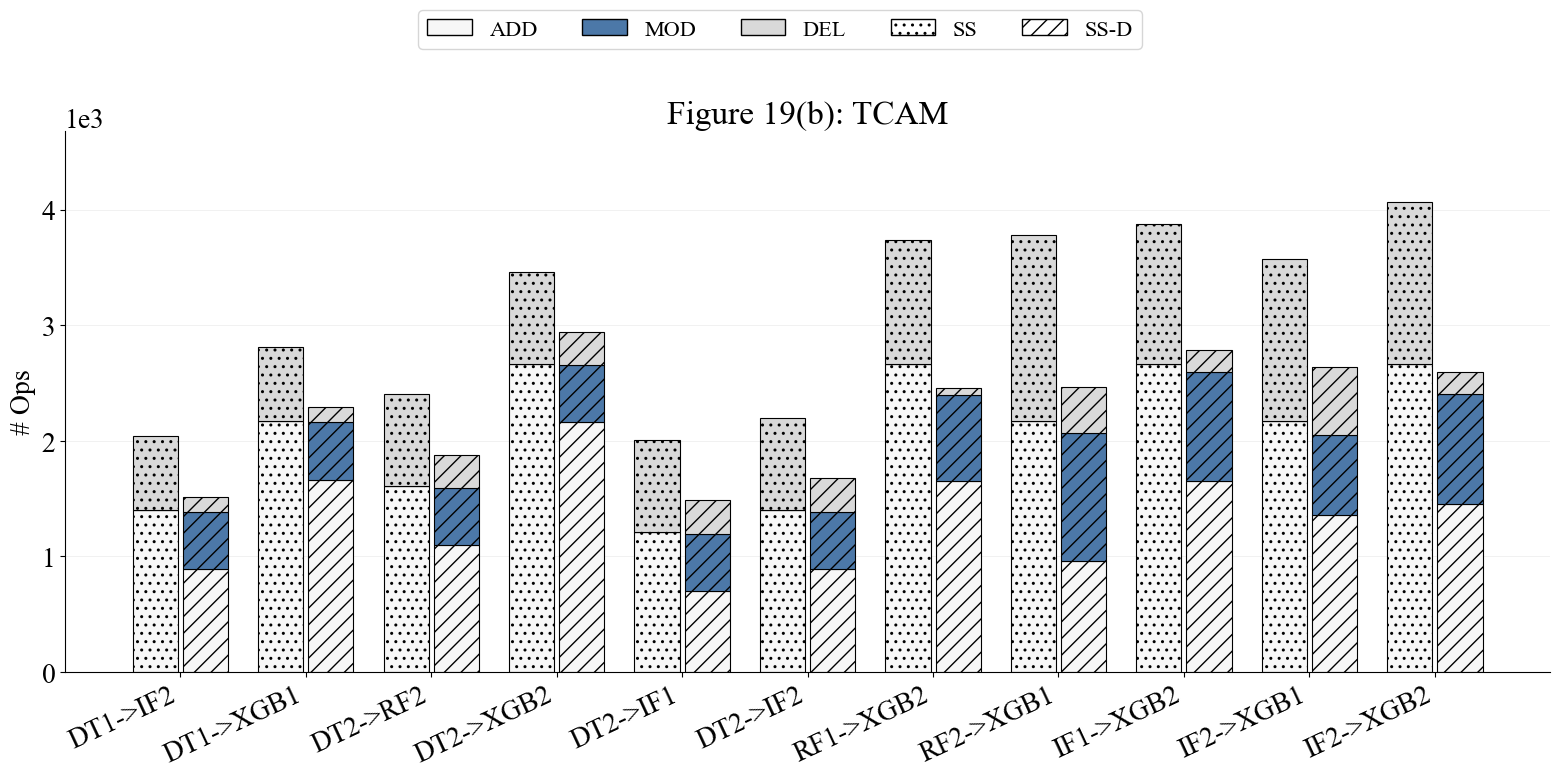

In [34]:
OTHER_TRANSITIONS = [
    ("DT1", "IF2"), ("DT1", "XGB1"), ("DT2", "RF2"), ("DT2", "XGB2"),
    ("DT2", "IF1"), ("DT2", "IF2"), ("DT1", "LR1"), ("DT1", "LR2"),
    ("DT2", "LR1"), ("DT2", "LR2"), ("RF1", "XGB2"), ("RF2", "XGB1"),
    ("IF1", "XGB2"), ("IF2", "XGB1"), ("IF2", "XGB2"),
    ("SVM1", "DT2"), ("SVM2", "DT1"),
]

fig_19a = plot_operation_counts(
    ss_results, OTHER_TRANSITIONS, "SS", "Figure 19(a): SRAM",
    baseline_results=baseline_sram_results,
)
plt.show()

# SS_T does not support the LR and SVM models in these transitions.
other_tcam_transitions = [
    pair for pair in OTHER_TRANSITIONS
    if all(not model.startswith(("LR", "SVM")) for model in pair)
]
fig_19b = plot_operation_counts(
    ss_t_results, other_tcam_transitions, "SS_T", "Figure 19(b): TCAM",
    baseline_results=baseline_tcam_results,
)
plt.show()